# 01 · Run analysis: where and why runs end

This notebook explores 2,000 runs played by the headless bot (`analysis/bot.py`). It's the same kind of exploratory analysis as a business case study, just on game data you generated yourself.

**The data.** Each run writes several tidy tables to `runs/`. We use two here:

| Table | One row per | Used for |
|---|---|---|
| `bot_runs.csv` | run | outcomes, causes of death, companion and class |
| `bot_floors.csv` | floor a run reached | the player's state on arrival, what happened on the floor, whether they died there |

**A design detail that matters later.** The bot accepts each sponsor contract on a coin flip. That makes the contracts a *randomised experiment*, so in section 5 we can measure what a deal actually does to your survival chances, not just what tends to happen alongside it.

To regenerate the data: `python analysis/bot.py --runs 2000 --workers 4` (about six minutes on four cores).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from common import (CLASS_COLOURS, MUTED, PET_COLOURS, SEQUENTIAL, TEXT_2, has_player_runs,
                    label_line_ends, load, pct_axis, style, value_grid, wilson)
from crawler.contracts import CONTRACTS

style()
runs = load("runs")
floors = load("floors")
print(f"{len(runs):,} runs, {len(floors):,} floor visits")
runs.head(3)

2,000 runs, 10,787 floor visits


,run_id,source,seed,pet,race,backstory,gender,cls,outcome,depth,...,kills,level,gold,viewers,peak_viewers,boxes,achievements,practice_levels,death_cause,deals
0,bot00000,bot,0,cat,none,dog_walker,nonbinary,none,collapse,2,...,10,3,65,64,605,7,4,7,Crushed when floor 2 collapsed,random
1,bot00001,bot,1,dog,elf,rideshare,male,brawler,victory,6,...,84,15,1507,3349,6103,22,8,45,NaN,random
2,bot00002,bot,2,budgie,hobgoblin,veteran,nonbinary,hype_man,killed,6,...,58,11,620,902,2539,13,7,37,Killed by Executive Producer Glorm on floor 6,random


## 1. How runs end

Three outcomes: you escape (victory), something kills you, or the floor collapses with you on it.

In [2]:
outcome = runs["outcome"].value_counts(normalize=True).rename("share").to_frame()
outcome["runs"] = runs["outcome"].value_counts()
outcome.style.format({"share": "{:.1%}", "runs": "{:,}"})

,share,runs
outcome,,
victory,62.6%,"1,253"
killed,26.8%,536
collapse,10.5%,211


## 2. Survival by floor

A **survival curve** shows the share of runs still going at each point. Every bot run ends (in victory or death), so here it's simply the share of runs that *reached* each floor. With real player data you'd also have *unfinished* runs (someone quits mid-run). Those are called **censored** observations and need a Kaplan-Meier estimator rather than a simple share; the idea is the same.

We draw one line per companion, each in a fixed colour that's reused in every chart.

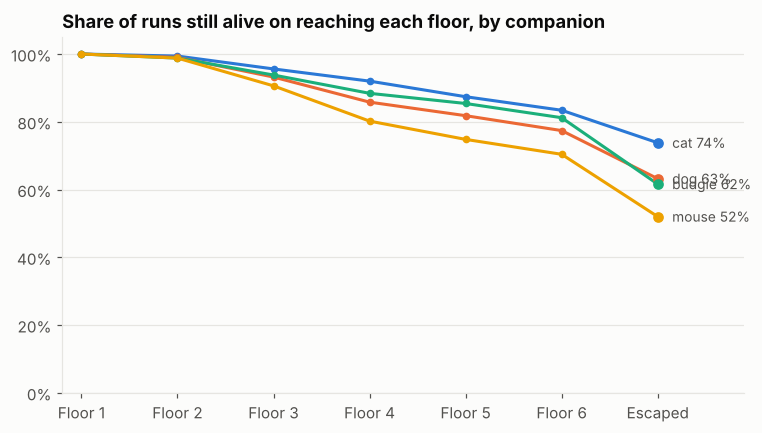

In [3]:
depths = range(1, 7)
fig, ax = plt.subplots()
lines, labels = [], []
for pet, colour in PET_COLOURS.items():
    d = runs.loc[runs["pet"] == pet]
    reached = [(d["depth"] >= k).mean() for k in depths]
    reached.append((d["outcome"] == "victory").mean())          # "floor 7" = escaped
    (line,) = ax.plot(list(depths) + [7], reached, color=colour, marker="o", markersize=4)
    lines.append(line)
    labels.append(pet)
label_line_ends(ax, lines, labels)
ax.set_xticks(list(depths) + [7], [f"Floor {k}" for k in depths] + ["Escaped"])
ax.set_ylim(0, 1.05)
pct_axis(ax)
ax.set_xlim(0.8, 7.9)
ax.set_title("Share of runs still alive on reaching each floor, by companion")
plt.show()

The steep drops are where runs end. The **hazard** at each floor is the chance of dying there *given you reached it*, which separates "this floor is deadly" from "few people get this far".

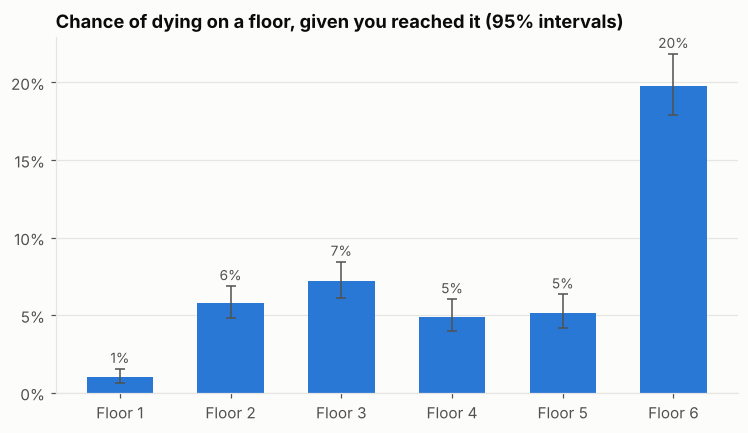

In [4]:
hazard = floors.groupby("depth")["died_here"].agg(["sum", "count"])
hazard["rate"] = hazard["sum"] / hazard["count"]
ci = hazard.apply(lambda r: wilson(r["sum"], r["count"]), axis=1, result_type="expand")
hazard[["lo", "hi"]] = ci

fig, ax = plt.subplots()
ax.bar(hazard.index, hazard["rate"], color=SEQUENTIAL, width=0.6)
ax.errorbar(hazard.index, hazard["rate"], yerr=[hazard["rate"] - hazard["lo"], hazard["hi"] - hazard["rate"]],
            fmt="none", ecolor=TEXT_2, capsize=3, linewidth=1)
for x, r in hazard.iterrows():
    ax.annotate(f"{r['rate']:.0%}", (x, r["hi"]), xytext=(0, 4), textcoords="offset points",
                ha="center", color=TEXT_2, fontsize=9)
ax.set_xticks(hazard.index, [f"Floor {k}" for k in hazard.index])
pct_axis(ax)
ax.set_title("Chance of dying on a floor, given you reached it (95% intervals)")
plt.show()

## 3. What does the killing

Bosses are optional on floors 1-5 but sealed in on floor 6. The cause of death shows whether a floor's danger comes from its boss or its regular monsters, and how often the timer wins instead.

In [5]:
dead = runs[runs["outcome"] != "victory"].copy()
dead["killer"] = (dead["death_cause"]
                  .str.replace(r"^Killed by (an? )?", "", regex=True)
                  .str.replace(r" on floor \d+$", "", regex=True)
                  .str.replace(r"^Crushed when floor \d+ collapsed$", "(floor collapse)", regex=True))
top = (dead.groupby(["depth", "killer"]).size().rename("deaths").reset_index()
       .sort_values(["depth", "deaths"], ascending=[True, False]).groupby("depth").head(3))
top["share of that floor's deaths"] = top["deaths"] / top.groupby("depth")["deaths"].transform("sum")
top.style.format({"share of that floor's deaths": "{:.0%}"}).hide(axis="index")

depth,killer,deaths,share of that floor's deaths
1,(floor collapse),15,75%
1,The Grease Trap King,5,25%
2,The Overdue Librarian,47,45%
2,(floor collapse),33,31%
2,Grumpy Skeleton,25,24%
3,Foreman Gristle,72,57%
3,(floor collapse),31,25%
3,Hex Cultist,23,18%
4,(floor collapse),48,58%
4,High Hexer Volka,23,28%


## 4. Companions, backstories, races and classes

Win rates with **95% confidence intervals**. With a few hundred runs per option, a gap of a few points could just be noise; the intervals show which differences are real. The Wilson interval is used because it behaves better than the textbook "p ± 1.96 × SE" when a rate is near 0% or 100%.

Companions keep their fixed colours. Backstories, races and classes have too many options to colour individually (more than the palette's eight safe hues), so they're shown in one colour with direct labels. Race and class only count runs that reached floor 3, where they're chosen.

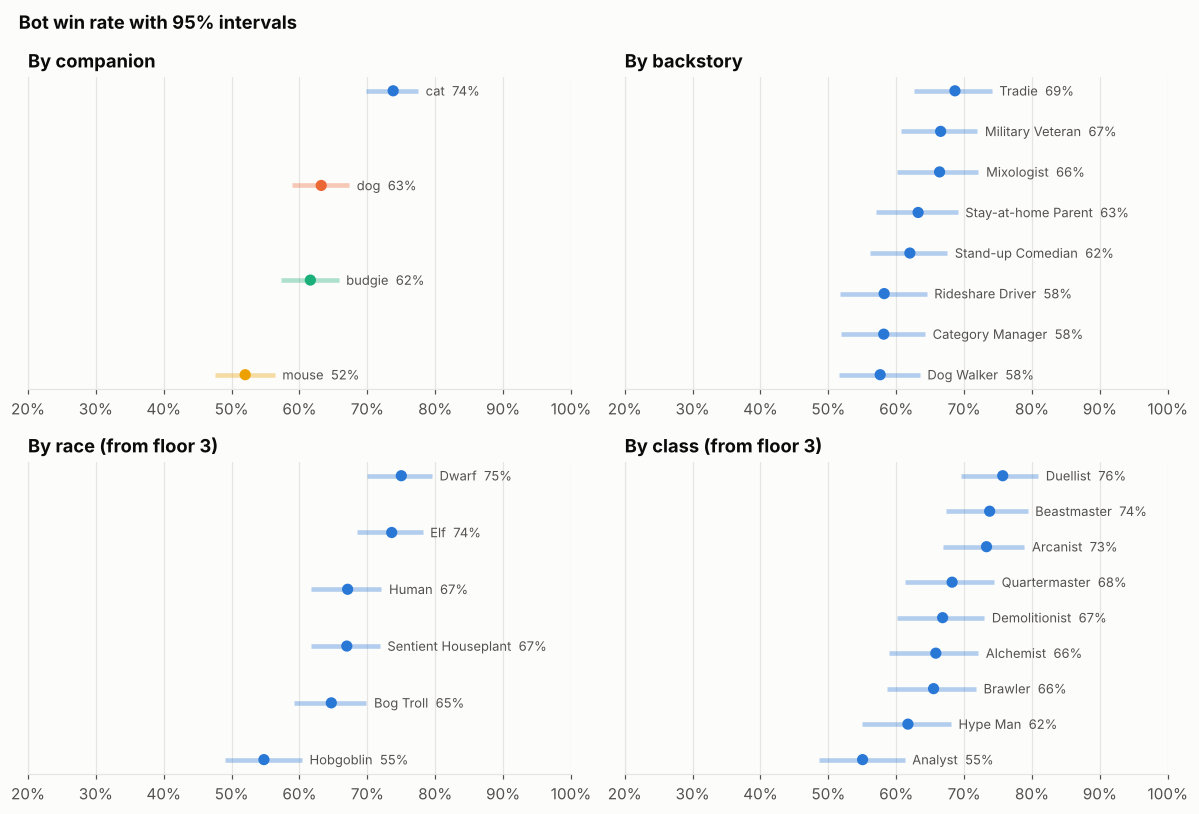

In [6]:
from crawler.character import BACKSTORIES
from crawler.classes import CLASSES, RACES

def interval_panel(ax, data, col, names, title, colours=None):
    g = data.groupby(col)["outcome"].agg(won=lambda s: (s == "victory").sum(), runs="size")
    g = g[g.index.isin(names)]
    g["rate"] = g["won"] / g["runs"]
    g = g.sort_values("rate")
    lo_hi = np.array([wilson(w, n) for w, n in zip(g["won"], g["runs"])])
    y = np.arange(len(g))
    cols = [colours[k] if colours else SEQUENTIAL for k in g.index]
    ax.hlines(y, lo_hi[:, 0], lo_hi[:, 1], color=cols, linewidth=3, alpha=0.35)
    ax.scatter(g["rate"], y, color=cols, s=40, zorder=3)
    for yy, (k, r), hi in zip(y, g.iterrows(), lo_hi[:, 1]):
        ax.annotate(f"{names[k]}  {r['rate']:.0%}", (hi, yy), xytext=(5, 0), textcoords="offset points",
                    va="center", color=TEXT_2, fontsize=8.5)
    ax.set_yticks([])
    ax.set_title(title)
    pct_axis(ax, "x")
    value_grid(ax)
    ax.set_xlim(0.2, 1.0)

reached3 = runs[runs["cls"] != "none"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
interval_panel(axes[0, 0], runs, "pet", {k: k for k in PET_COLOURS}, "By companion", PET_COLOURS)
interval_panel(axes[0, 1], runs, "backstory", {k: v["name"] for k, v in BACKSTORIES.items()}, "By backstory")
interval_panel(axes[1, 0], reached3, "race", {k: v["name"] for k, v in RACES.items()}, "By race (from floor 3)")
interval_panel(axes[1, 1], reached3, "cls", {k: v["name"] for k, v in CLASSES.items()}, "By class (from floor 3)")
fig.suptitle("Bot win rate with 95% intervals", x=0.02, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Reading it.** Where two intervals don't overlap, the difference is very unlikely to be chance. Two caveats keep this honest:

- These are *bot* win rates. The Analyst's skill only shows information, and the bot can't use information, so the Analyst looks weaker here than it will in human hands. A model is only as good as the behaviour it's measuring.
- Race and class are chosen on floor 3, so their rates leave out the runs that died earlier. Comparing them with the companion and backstory rates directly would mix two different groups of runs.
- The mouse is designed to run away when hurt, so it's missing from many boss fights. That's a deliberate trade-off in the game design, and it costs about 20 points of win rate for this bot.

## 5. Sponsor deals: a randomised experiment

Comparing floors where a deal was signed with floors where it wasn't usually suffers from **confounding**: if strong players took more deals, deal floors would look safer even if the deals were harmful.

Here the bot flips a coin for every offer, so signing is independent of how the run is going. The difference in death rates is then a fair estimate of each deal's **causal effect**. We compare each contract's floors with unsigned floors (floor 2 onwards, since deals start there).

In [7]:
f2 = floors[floors["depth"] >= 2]
base = f2[f2["contract"] == "none"]
base_rate = base["died_here"].mean()
rows = []
for contract, g in f2[f2["contract"] != "none"].groupby("contract"):
    diff = g["died_here"].mean() - base_rate
    # Standard error of a difference in two proportions.
    se = np.sqrt(g["died_here"].var(ddof=1) / len(g) + base["died_here"].var(ddof=1) / len(base))
    rows.append(dict(contract=contract, floors=len(g), death_rate=g["died_here"].mean(),
                     effect=diff, low=diff - 1.96 * se, high=diff + 1.96 * se,
                     extra_gold=g["gold_earned"].mean() - base["gold_earned"].mean(),
                     extra_viewers=g["viewers_gained"].mean() - base["viewers_gained"].mean()))
deals = pd.DataFrame(rows).set_index("contract").sort_values("effect")
print(f"Floors without a deal: {len(base):,}, death rate {base_rate:.1%}")
deals.rename(index=lambda k: CONTRACTS[k]["name"]).style.format({"death_rate": "{:.1%}", "effect": "{:+.1%}", "low": "{:+.1%}", "high": "{:+.1%}",
                    "extra_gold": "{:+.0f}", "extra_viewers": "{:+.0f}"})

Floors without a deal: 5,694, death rate 6.6%


,floors,death_rate,effect,low,high,extra_gold,extra_viewers
contract,,,,,,,
Snack Sprint,741,5.7%,-0.9%,-2.7%,+0.9%,-5,+358
Power Nap Package,762,6.7%,+0.1%,-1.7%,+2.0%,-56,+23
Gloop Blitz,790,10.3%,+3.7%,+1.5%,+5.9%,+80,-14
Hazard Pay,800,22.5%,+15.9%,+13.0%,+18.9%,+139,+222


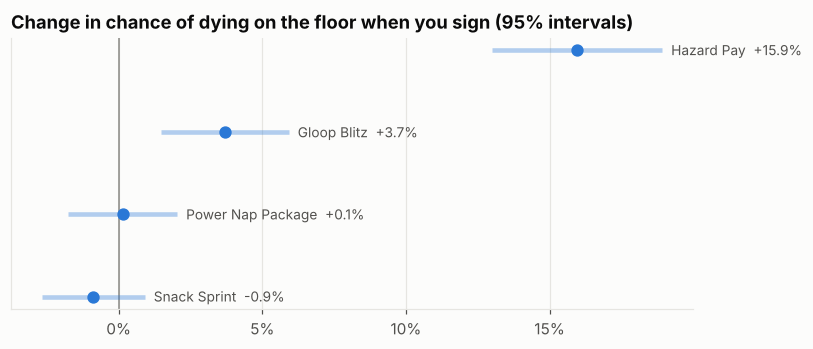

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(deals))
ax.axvline(0, color=MUTED, linewidth=1)
ax.hlines(y, deals["low"], deals["high"], color=SEQUENTIAL, linewidth=3, alpha=0.35)
ax.scatter(deals["effect"], y, color=SEQUENTIAL, s=50, zorder=3)
for yy, (name, r) in zip(y, deals.iterrows()):
    ax.annotate(f"{CONTRACTS[name]['name']}  {r['effect']:+.1%}", (r["high"], yy), xytext=(6, 0),
                textcoords="offset points",
                va="center", color=TEXT_2, fontsize=9)
ax.set_yticks([])
pct_axis(ax, "x")
value_grid(ax)
ax.set_title("Change in chance of dying on the floor when you sign (95% intervals)")
plt.show()

**What this says.** Deals whose interval crosses zero are statistically indistinguishable from "no effect" on survival, so whatever they pay is close to free. A deal whose whole interval sits to the right of zero genuinely gets people killed, and its extra gold and viewers are the price the sponsor pays for that risk.

This is the same logic as an A/B test or a trade promotion trial: random assignment is what lets you read the difference as cause and effect.

## 6. Practice skills

Skills level up by doing the thing: stomping small monsters trains Stomping, getting hit and living trains Pain Tolerance. `bot_practice.csv` has one row per skill per run with the level reached.

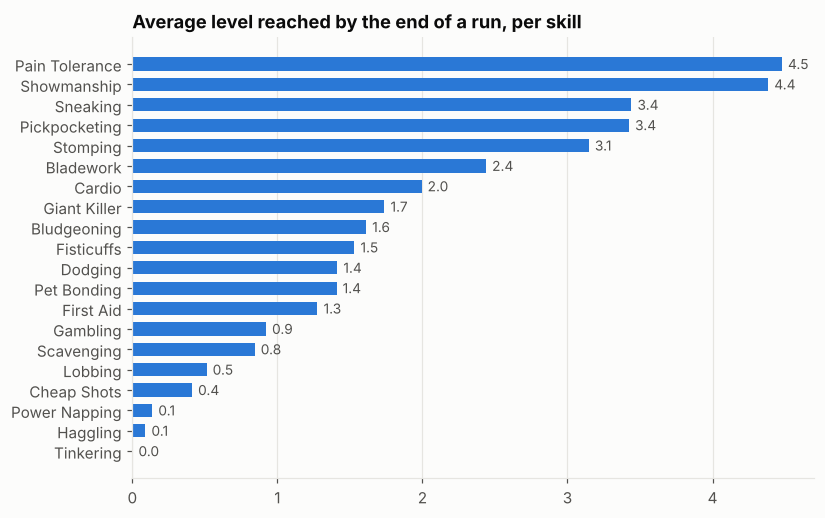

In [9]:
from crawler.practice import SKILLS as PRACTICE
practice = load("practice")
mean_level = practice.groupby("skill")["level"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh([PRACTICE[k]["name"] for k in mean_level.index], mean_level.values, color=SEQUENTIAL, height=0.65)
for i, v in enumerate(mean_level.values):
    ax.annotate(f"{v:.1f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center",
                color=TEXT_2, fontsize=9)
value_grid(ax)
ax.set_title("Average level reached by the end of a run, per skill")
plt.show()

The bot leans on a few skills (it walks, fights and gets hit a lot) and never touches others; it doesn't craft, so Tinkering stays at zero. A human player who haggles or naps will see a different profile.

**A trap: reverse causality.** Winning runs end with higher skill levels. Does practising make you win?

In [10]:
total = practice.groupby("run_id")["level"].sum().rename("total_levels")
r = runs.set_index("run_id").join(total)
r["won"] = r["outcome"] == "victory"
display(r.groupby("won")[["total_levels", "turns", "depth"]].mean().round(1))
print("Correlation of total levels with turns played:", round(r["total_levels"].corr(r["turns"]), 2))

,total_levels,turns,depth
won,,,
False,25.8,1228.4,4.4
True,40.8,1640.0,6.0


Correlation of total levels with turns played: 0.66


Winners have more levels, but they also **played longer** and went deeper: a run that dies on floor 2 has no time to practise anything. Total levels and turns played are strongly correlated, so levels are partly a consequence of surviving, not just a cause of it. Comparing winners with losers can't separate the two, so it says little about how much the skills actually help.

To measure the skills' real effect you need an experiment: play the same seeds with skills switched on and off. That's how they were balanced. On 400 seeds, the bot won 53% of runs with every skill switched off. The first version of the skills pushed that to 79%, which was far too strong. Switching skills off one at a time showed no single culprit (each was worth 0 to 6 points), so the whole system was slowed and every combat bonus trimmed. The shipped version lands at about 63%: practising matters, but it doesn't play the game for you.

## 7. Your own runs

When you play the real game, each finished run is logged to `runs/player_*.csv` with `source = "player"`. Once you have a few, this cell puts you next to the bot.

In [11]:
if has_player_runs():
    allruns = load("runs", source="all")
    summary = allruns.groupby("source").agg(runs=("run_id", "size"),
                                            win_rate=("outcome", lambda s: (s == "victory").mean()),
                                            mean_floor=("depth", "mean"), median_viewers=("viewers", "median"))
    display(summary.style.format({"win_rate": "{:.0%}", "mean_floor": "{:.1f}", "median_viewers": "{:,.0f}"}))
else:
    print("No player runs logged yet. Play a few games (python main.py) and re-run this notebook.")

No player runs logged yet. Play a few games (python main.py) and re-run this notebook.
